In [1]:
import pandas as pd
import glob

# Path to all CSVs (adjust this to your Kaggle download folder)
path = "./CICIDS2017/"  

# Load all CSV files into a list
all_files = glob.glob(path + "*.csv")

# Combine into one DataFrame
df_list = [pd.read_csv(file) for file in all_files]
df = pd.concat(df_list, ignore_index=True)
df = df.sample(n=20000, random_state=42)

print("Combined shape:", df.shape)
print("Columns:", df.columns[:10], "...")
print("Unique labels:", df[' Label'].unique())


Combined shape: (20000, 79)
Columns: Index([' Destination Port', ' Flow Duration', ' Total Fwd Packets',
       ' Total Backward Packets', 'Total Length of Fwd Packets',
       ' Total Length of Bwd Packets', ' Fwd Packet Length Max',
       ' Fwd Packet Length Min', ' Fwd Packet Length Mean',
       ' Fwd Packet Length Std'],
      dtype='object') ...
Unique labels: ['BENIGN' 'DoS Hulk' 'PortScan' 'DDoS' 'DoS slowloris' 'DoS GoldenEye'
 'FTP-Patator' 'DoS Slowhttptest' 'Bot' 'SSH-Patator' 'Web Attack � XSS'
 'Web Attack � Brute Force' 'Infiltration']


In [2]:
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE
from scipy.stats import mode
import time
import os
from joblib import dump, load
import os
from scipy.stats import mode
from tqdm import tqdm
from sklearn.decomposition import PCA
import torch
import torch.nn as nn
import torch.optim as optim
    

In [3]:
SEED = 42
NUM_FEATURES = 13

In [4]:
# df.dtypes
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20000 entries, 746827 to 609904
Data columns (total 79 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0    Destination Port             20000 non-null  int64  
 1    Flow Duration                20000 non-null  int64  
 2    Total Fwd Packets            20000 non-null  int64  
 3    Total Backward Packets       20000 non-null  int64  
 4   Total Length of Fwd Packets   20000 non-null  int64  
 5    Total Length of Bwd Packets  20000 non-null  int64  
 6    Fwd Packet Length Max        20000 non-null  int64  
 7    Fwd Packet Length Min        20000 non-null  int64  
 8    Fwd Packet Length Mean       20000 non-null  float64
 9    Fwd Packet Length Std        20000 non-null  float64
 10  Bwd Packet Length Max         20000 non-null  int64  
 11   Bwd Packet Length Min        20000 non-null  int64  
 12   Bwd Packet Length Mean       20000 non-null  float64
 13  

In [5]:
df[' Label'].unique()

array(['BENIGN', 'DoS Hulk', 'PortScan', 'DDoS', 'DoS slowloris',
       'DoS GoldenEye', 'FTP-Patator', 'DoS Slowhttptest', 'Bot',
       'SSH-Patator', 'Web Attack � XSS', 'Web Attack � Brute Force',
       'Infiltration'], dtype=object)

In [6]:
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()

# Strip spaces from column names
df.columns = df.columns.str.strip()

In [7]:
categorical_cols = df.select_dtypes(include='object').columns
label_encoders = {}

le = LabelEncoder()
for col in categorical_cols:
    df[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le
    print(f"\nColumn: {col}")
    print(dict(zip(le.classes_, le.transform(le.classes_))))


Column: Label
{'BENIGN': 0, 'Bot': 1, 'DDoS': 2, 'DoS GoldenEye': 3, 'DoS Hulk': 4, 'DoS Slowhttptest': 5, 'DoS slowloris': 6, 'FTP-Patator': 7, 'Infiltration': 8, 'PortScan': 9, 'SSH-Patator': 10, 'Web Attack � Brute Force': 11, 'Web Attack � XSS': 12}


In [8]:
feature_names = df.columns
X = df.drop('Label', axis=1)   # note: 'Label' (no space after cleaning)
y = df['Label']

# Train/test split
SEED = 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Original class distribution (train): {np.bincount(y_train)}")

Original class distribution (train): [12867    15   676    57  1272    33    34    51     1   940    28     2
     6]


In [9]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [10]:
pca = PCA(n_components=NUM_FEATURES, random_state=SEED)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test_scaled)

print("Features Selected: ")
for i, component in enumerate(pca.components_):
    important_idx = np.argmax(np.abs(component))
    print(f"Principal Component {i+1}: most important feature is '{feature_names[important_idx]}'")

Features Selected: 
Principal Component 1: most important feature is 'Flow IAT Max'
Principal Component 2: most important feature is 'Total Backward Packets'
Principal Component 3: most important feature is 'Fwd IAT Min'
Principal Component 4: most important feature is 'Avg Fwd Segment Size'
Principal Component 5: most important feature is 'min_seg_size_forward'
Principal Component 6: most important feature is 'ACK Flag Count'
Principal Component 7: most important feature is 'Active Max'
Principal Component 8: most important feature is 'Fwd IAT Min'
Principal Component 9: most important feature is 'Active Mean'
Principal Component 10: most important feature is 'URG Flag Count'
Principal Component 11: most important feature is 'RST Flag Count'
Principal Component 12: most important feature is 'Fwd URG Flags'
Principal Component 13: most important feature is 'Fwd PSH Flags'


In [11]:
X_train = X_train_pca
X_test = X_test_pca

print(X_train.shape, X_test.shape)

(15982, 13) (3996, 13)


In [12]:
n_layers = 6
n_classes = len(y.unique())

dev = qml.device("default.qubit", wires=NUM_FEATURES)

@qml.qnode(dev)
def qnn_circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(NUM_FEATURES))
    qml.StronglyEntanglingLayers(weights, wires=range(NUM_FEATURES))
    return [qml.expval(qml.PauliZ(i)) for i in range(NUM_FEATURES)]

qnode = qml.QNode(qnn_circuit, dev, interface="torch")

class QNNClassifierMulti(nn.Module):
    def __init__(self, n_layers, n_qubits, n_classes):
        super().__init__()
        weight_shapes = {"weights": (n_layers, n_qubits, 3)}
        self.qlayer = qml.qnn.TorchLayer(qnode, weight_shapes)
        self.fc = nn.Linear(n_qubits, n_classes)  # output = n_classes
    
    def forward(self, x):
        x = self.qlayer(x)
        x = self.fc(x)
        return x  # logits for each class

# class QNNClassifier(nn.Module):
#     def __init__(self, n_layers, n_qubits):
#         super().__init__()
#         weight_shapes = {"weights": (n_layers, n_qubits, 3)}
#         self.qlayer = qml.qnn.TorchLayer(qnode, weight_shapes)
#         self.fc = nn.Linear(n_qubits, 1)
    
#     def forward(self, x):
#         x = self.qlayer(x)
#         x = self.fc(x)
#         return x  # No sigmoid here




In [ ]:
X_train_300 = X_train[:300]
X_test_100 = X_test[:100]
y_train_300 = y_train[:300]
y_test_100 = y_test[:100]

loss_values = []

# Prepare data
X_train_tensor = torch.tensor(X_train_300, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_300.values, dtype=torch.float32).unsqueeze(1)
X_test_tensor = torch.tensor(X_test_100, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_100.values, dtype=torch.float32).unsqueeze(1)

# Use DataLoader for mini-batch training
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# Model, loss, optimizer
model = QNNClassifier(n_layers=n_layers, n_qubits=NUM_FEATURES)
criterion = nn.BCEWithLogitsLoss() # used for binary classification
optimizer = optim.Adam(model.parameters(), lr=0.01)


# Training loop
epochs = 100
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    epoch_loss = running_loss / len(train_loader)
    loss_values.append(epoch_loss)
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(train_loader):.4f}")

# Evaluation
model.eval()
# with torch.no_grad():
#     y_pred_logits = model(X_test_tensor)
#     qnn_preds = (torch.sigmoid(y_pred_logits) > 0.5).int().squeeze().numpy()

with torch.no_grad():
    y_pred_logits = model(X_test_tensor)  # shape: (N, 1)
    qnn_sigmoid = torch.sigmoid(y_pred_logits).squeeze()  # shape: (N,)
    qnn_preds = (qnn_sigmoid > 0.5).int().numpy()

    # Convert to probability distribution over 2 classes: [P(class 0), P(class 1)]
    qnn_probs = torch.stack([1 - qnn_sigmoid, qnn_sigmoid], dim=1).cpu().numpy()  # shape: (N, 2)


accuracy_qnn = accuracy_score(y_test_100, qnn_preds)
print(f"QNN Accuracy on Test Data: {accuracy_qnn:.4f}")

print("Classification Report:\n", classification_report(y_test_100, qnn_preds))

cm = confusion_matrix(y_test_100, qnn_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"])
plt.title("Confusion Matrix - QNN")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

NameError: name 'QNNClassifier' is not defined

: 

In [ ]:
# Prepare data (example subset)
X_train_tensor = torch.tensor(X_train[:3000], dtype=torch.float32)
y_train_tensor = torch.tensor(y_train[:3000].values, dtype=torch.long)  # long for CE loss
X_test_tensor = torch.tensor(X_test[:1000], dtype=torch.float32)
y_test_tensor = torch.tensor(y_test[:1000].values, dtype=torch.long)

# Dataloader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# Model, loss, optimizer
model_multi = QNNClassifierMulti(n_layers=n_layers, n_qubits=NUM_FEATURES, n_classes=n_classes)
criterion = nn.CrossEntropyLoss() # removed BCEWithLogitsLoss because it is used for binary calssification
optimizer = optim.Adam(model_multi.parameters(), lr=0.01)

# Training loop
epochs = 100
for epoch in range(epochs):
    model_multi.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model_multi(X_batch)              # shape: (batch, n_classes)
        loss = criterion(outputs, y_batch)          # CE loss expects logits + class indices
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    # if (epoch+1) % 10 == 0:
    print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(train_loader):.4f}")


model_multi.eval()
with torch.no_grad():
    logits = model_multi(X_test_tensor)       # (N, n_classes)
    probs = torch.softmax(logits, dim=1)      # class probabilities
    preds = torch.argmax(probs, dim=1).numpy()

acc = accuracy_score(y_test_tensor, preds)
print(f"Multiclass QNN Accuracy: {acc:.4f}")


Epoch 1/100, Loss: 1.7291
Epoch 2/100, Loss: 0.9120
Epoch 3/100, Loss: 0.7279
Epoch 4/100, Loss: 0.6434
Epoch 5/100, Loss: 0.5825
Epoch 6/100, Loss: 0.5292
Epoch 7/100, Loss: 0.4866
Epoch 8/100, Loss: 0.4557
Epoch 9/100, Loss: 0.4323
Epoch 10/100, Loss: 0.4136
Epoch 11/100, Loss: 0.3952
Epoch 12/100, Loss: 0.3813
Epoch 13/100, Loss: 0.3684
Epoch 14/100, Loss: 0.3581
Epoch 15/100, Loss: 0.3481
Epoch 16/100, Loss: 0.3358
Epoch 17/100, Loss: 0.3256
Epoch 18/100, Loss: 0.3177
Epoch 19/100, Loss: 0.3105
Epoch 20/100, Loss: 0.3030
Epoch 21/100, Loss: 0.2941
Epoch 22/100, Loss: 0.2910
Epoch 23/100, Loss: 0.2886
Epoch 24/100, Loss: 0.2806
Epoch 25/100, Loss: 0.2757
Epoch 26/100, Loss: 0.2737
Epoch 27/100, Loss: 0.2692
Epoch 28/100, Loss: 0.2679
Epoch 29/100, Loss: 0.2630
Epoch 30/100, Loss: 0.2568
Epoch 31/100, Loss: 0.2568
Epoch 32/100, Loss: 0.2556
Epoch 33/100, Loss: 0.2487
Epoch 34/100, Loss: 0.2463
Epoch 35/100, Loss: 0.2426
Epoch 36/100, Loss: 0.2434
Epoch 37/100, Loss: 0.2390
Epoch 38/1

ValueError: Number of classes, 9, does not match size of target_names, 13. Try specifying the labels parameter

In [ ]:
print("Classification Report:\n", 
      classification_report(
          y_test_tensor, 
          preds, 
          target_names=[str(c) for c in np.unique(y_test_tensor)]
      ))

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.99      0.96       805
           2       0.97      0.79      0.87        43
           3       0.00      0.00      0.00         3
           4       0.91      0.84      0.87        87
           5       0.00      0.00      0.00         2
           6       0.00      0.00      0.00         3
           7       0.00      0.00      0.00         1
           9       1.00      0.47      0.64        55
          10       0.00      0.00      0.00         1

    accuracy                           0.93      1000
   macro avg       0.42      0.34      0.37      1000
weighted avg       0.92      0.93      0.92      1000



/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


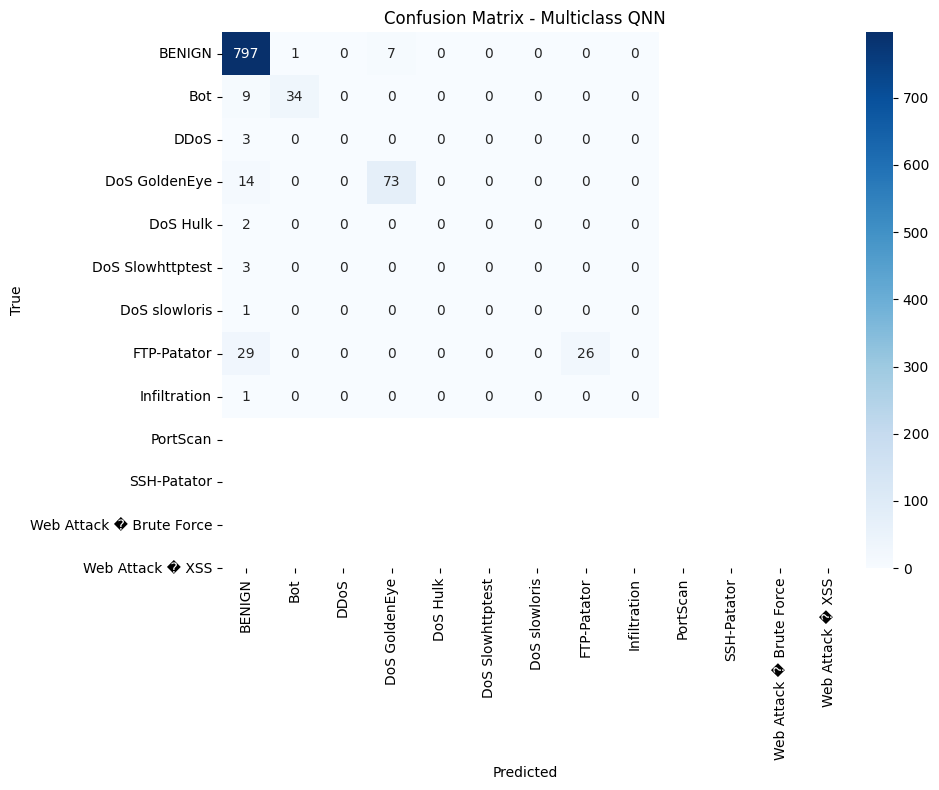

In [ ]:
cm = confusion_matrix(y_test_tensor, preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.title("Confusion Matrix - Multiclass QNN")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()